In [ ]:
Name Rohan Prakash Wayal
Roll no: 68
Problem Statement:-Apply PCA to a high-dimensional dataset and compare the number of features before and after PCA, visualize reduced dimensions, and evaluate the impact on classification performance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [3]:
data = load_breast_cancer()
X = data.data
y = data.target

In [4]:
("Dataset shape:", X.shape)

('Dataset shape:', (569, 30))

In [5]:
("Number of samples:", X.shape[0])

('Number of samples:', 569)

In [6]:
("Original number of features:", X.shape[1])

('Original number of features:', 30)

In [7]:
("Target classes:", data.target_names)

('Target classes:', array(['malignant', 'benign'], dtype='<U9'))

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

("Training samples:", X_train.shape[0])

('Training samples:', 455)

In [9]:
("Testing samples:", X_test.shape[0])

('Testing samples:', 114)

In [10]:
model_original = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

model_original.fit(X_train, y_train)
y_pred_original = model_original.predict(X_test)

accuracy_original = accuracy_score(y_test, y_pred_original)
(f"Original number of features: {X_train.shape[1]}")

'Original number of features: 30'

In [11]:
(f"Accuracy without PCA: {accuracy_original * 100:.2f}%")

'Accuracy without PCA: 98.25%'

In [12]:
pca_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=5000))
])

pca_model.fit(X_train, y_train)
y_pred_pca = pca_model.predict(X_test)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
pca = pca_model.named_steps["pca"]
("Original number of features:", X_train.shape[1])

('Original number of features:', 30)

In [13]:
("Number of features after PCA:", pca.n_components_)

('Number of features after PCA:', np.int64(10))

In [14]:
(f"Explained variance retained: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

'Explained variance retained: 95.27%'

In [15]:
(f"Accuracy with PCA: {accuracy_pca * 100:.2f}%")

'Accuracy with PCA: 97.37%'

In [16]:
("Classification Performance Comparison")

'Classification Performance Comparison'

In [17]:
(f"Accuracy without PCA: {accuracy_original * 100:.2f}%")

'Accuracy without PCA: 98.25%'

In [18]:
(f"Accuracy with PCA:    {accuracy_pca * 100:.2f}%")

'Accuracy with PCA:    97.37%'

In [19]:
(f"Accuracy difference:  {(accuracy_pca - accuracy_original) * 100:+.2f} percentage points")

'Accuracy difference:  -0.88 percentage points'

In [20]:
("Classification report after PCA:")

'Classification report after PCA:'

In [21]:
print(classification_report(
    y_test,
    y_pred_pca,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



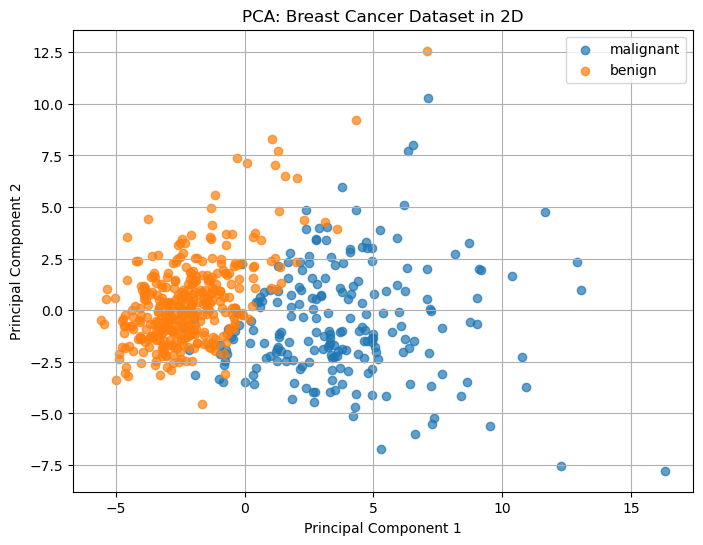

Variance explained by first two components: 63.24%


In [22]:
X_scaled_visual = StandardScaler().fit_transform(X)

pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled_visual)

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(data.target_names):
    plt.scatter(
        X_2d[y == class_id, 0],
        X_2d[y == class_id, 1],
        label=class_name,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Breast Cancer Dataset in 2D")
plt.legend()
plt.grid(True)
plt.show()

print(f"Variance explained by first two components: {pca_2d.explained_variance_ratio_.sum() * 100:.2f}%")

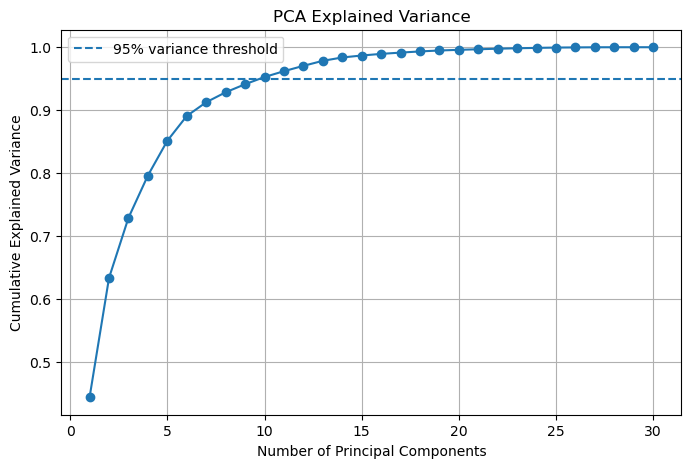

Components needed to retain at least 95% variance: 10


In [23]:
X_train_scaled = StandardScaler().fit_transform(X_train)
pca_full = PCA().fit(X_train_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", label="95% variance threshold")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

components_for_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed to retain at least 95% variance:", components_for_95)

In [24]:
import pandas as pd

comparison = pd.DataFrame({
    "Measure": [
        "Number of features",
        "Test accuracy"
    ],
    "Before PCA": [
        X_train.shape[1],
        f"{accuracy_original * 100:.2f}%"
    ],
    "After PCA": [
        pca.n_components_,
        f"{accuracy_pca * 100:.2f}%"
    ]
})

comparison

,Measure,Before PCA,After PCA
0,Number of features,30,10
1,Test accuracy,98.25%,97.37%
